# **Fase 2 — Formulación y contraste de hipótesis**
**Gasto diario de la obra vs. días de ampliación solicitados**

Nivel de significancia declarado de antemano: **α = 0,05** (bilateral) para todas las pruebas.

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import statsmodels.formula.api as smf
import statsmodels.api as sm
from scipy.stats import shapiro, levene
from statsmodels.stats.multitest import multipletests


In [3]:

df = pd.read_csv('output/dataset_final.csv')

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14268 entries, 0 to 14267
Data columns (total 41 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   award_id                          14268 non-null  object 
 1   release_id                        14268 non-null  object 
 2   fecha_adj                         14268 non-null  object 
 3   monto_adj                         14268 non-null  int64  
 4   log_monto                         14268 non-null  float64
 5   anio                              14268 non-null  int64  
 6   mes                               14268 non-null  int64  
 7   contract_id                       14264 non-null  object 
 8   fecha_firma                       14264 non-null  object 
 9   plazo_dias                        14264 non-null  float64
 10  ruc                               14268 non-null  object 
 11  proveedor                         14268 non-null  object 
 12  prov

In [5]:
def verificar_p_value(p_value, significancia=0.05):
  if p_value < significancia:
    print("Rechazar la hipótesis nula")
  else:
    print("No hay evidencia suficiente para rechazar la hipótesis nula")

alpha = 0.05
rng = np.random.default_rng(42)

# **Preparación de las variables**

- **Gasto diario** = `monto_adj / plazo_dias` (monto adjudicado dividido el plazo contractual en días). Se excluyen los contratos con `plazo_dias` nulo o igual a 0, porque el cociente no está definido.
- **Días de ampliación** = `dias_ampliacion_total` (suma de los días de ampliación de plazo solicitados en el contrato).
- Como ambas variables son muy asimétricas, se trabaja además con sus transformaciones logarítmicas (`log1p`) para la prueba paramétrica.

In [ ]:
#tenemos en cuenta solo los contratos de obras, y eliminamos los que tienen valores nulos en las columnas de interes.
datos = df[df['categoria_principal'] == 'works'].copy()
datos = datos.dropna(subset=["monto_adj", "plazo_dias", "dias_ampliacion_total"])
datos = datos[datos["plazo_dias"] > 0].copy()

#creamos nuevas columnas para el gasto diario, log(gasto diario), log(días de ampliación) y log(plazo),
#  y una columna binaria que indica si hubo ampliación de plazo o no.
datos["gasto_diario"] = datos["monto_adj"] / datos["plazo_dias"]
datos["log_gasto_diario"] = np.log1p(datos["gasto_diario"])
datos["log_dias_ampl"] = np.log1p(datos["dias_ampliacion_total"])
datos["log_plazo"] = np.log1p(datos["plazo_dias"])
datos["con_ampliacion"] = (datos["dias_ampliacion_total"] > 0).astype(int)

print("Contratos analizados:", len(datos), "de", len(df))
print("Con ampliación de plazo (días > 0):", datos["con_ampliacion"].sum(),
      f"({datos['con_ampliacion'].mean():.1%})")
datos[["gasto_diario", "dias_ampliacion_total", "plazo_dias"]].describe().round(2)

Contratos analizados: 1240 de 14268
Con ampliación de plazo (días > 0): 143 (11.5%)


,gasto_diario,dias_ampliacion_total,plazo_dias
count,1.240000e+03,1240.00,1240.00
mean,4.593538e+06,30.72,164.12
std,1.162289e+07,132.66,191.90
min,4.259259e+04,0.00,3.00
25%,8.105289e+05,0.00,60.00
50%,1.762749e+06,0.00,90.00
75%,4.451655e+06,0.00,186.75
max,2.259550e+08,1825.00,2700.00


# **Hipótesis: gasto diario y días de ampliación**

**Lenguaje formal** (ρ = correlación poblacional entre el gasto diario y los días de ampliación):

H₀: ρ = 0

H₁: ρ ≠ 0

**Lenguaje natural**

H₀: No existe una relación significativa entre el gasto diario de una obra y la cantidad de días de ampliación solicitados.

H₁: Existe una relación significativa entre el gasto diario de una obra y la cantidad de días de ampliación solicitados.

**Nivel de significancia:** α = 0,05 (prueba bilateral).

# **Selección y justificación de la prueba**

| Criterio | Situación |
|---|---|
| Tipo de pregunta | Significancia de una correlación entre dos variables |
| Variables | Ambas cuantitativas (gasto diario en Gs. por día; días de ampliación) |
| Prueba paramétrica | **r de Pearson**, con intervalo de confianza por transformación de Fisher |
| Alternativa no paramétrica | **rho de Spearman**, con intervalo por bootstrap |
| Supuestos de Pearson | Normalidad bivariada, relación lineal, independencia de las observaciones |

Si no se cumple la normalidad, la prueba principal pasa a ser Spearman y se documenta.

Dado que la gran mayoría de las obras no solicitó ampliación (`dias_ampliacion_total = 0`), se contrasta la hipótesis en **dos poblaciones**: (A) todas las obras y (B) solo las obras que sí solicitaron ampliación. Esto da cuatro contrastes (Pearson y Spearman en A y en B) sobre la misma familia de hipótesis, por lo que se aplica corrección por comparaciones múltiples.

# **Verificación de supuestos**

Muestra A (todas las obras): 1240
Muestra B (solo con ampliación): 143


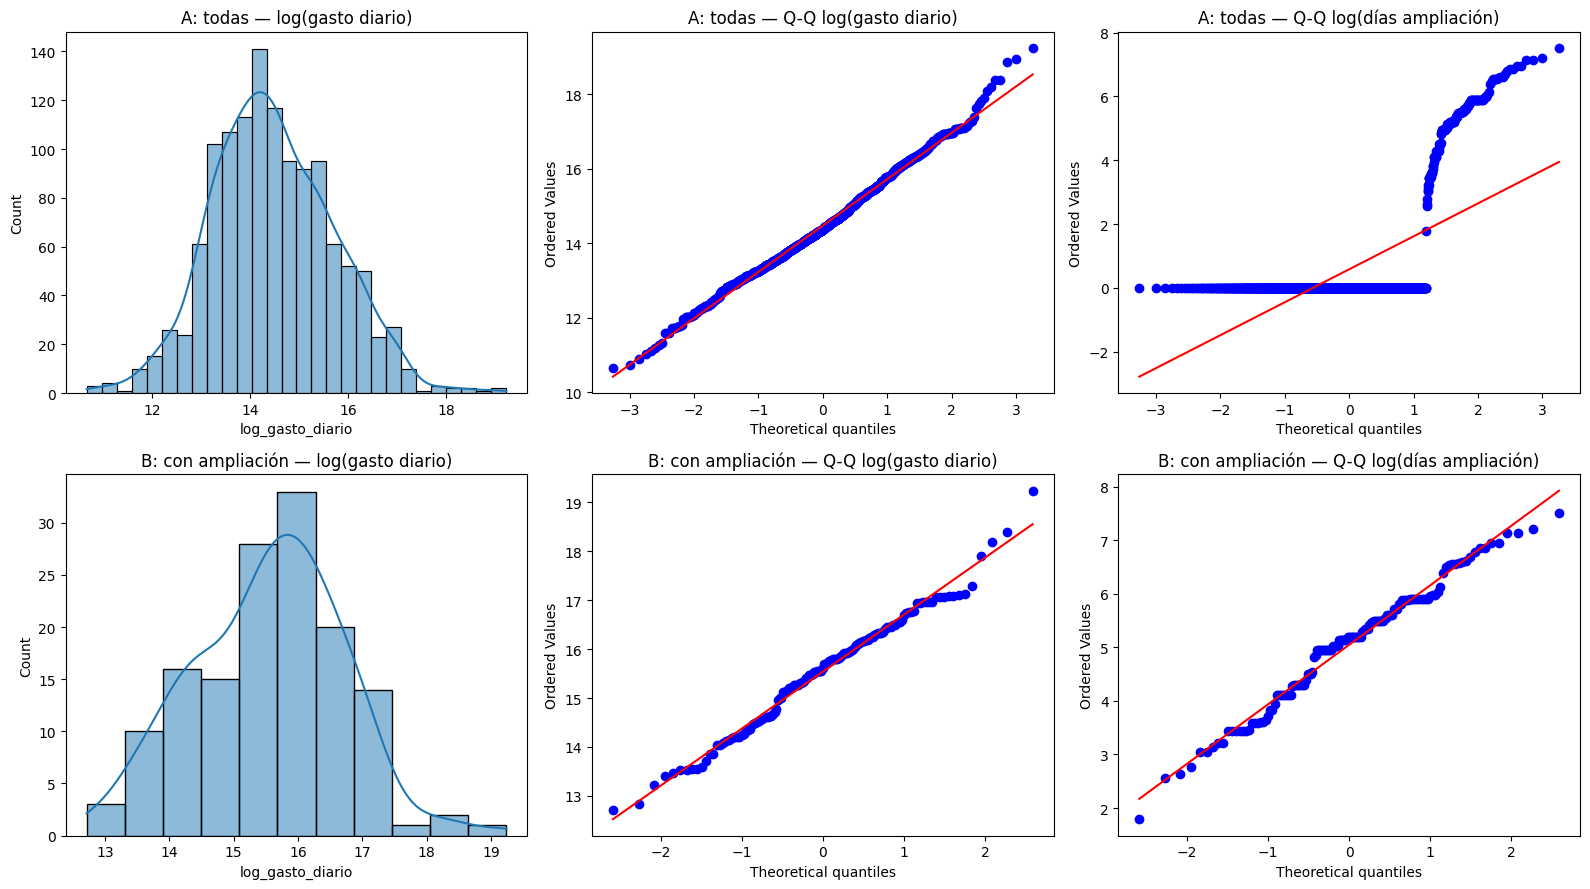

In [ ]:
A = datos[["log_gasto_diario", "log_dias_ampl", "gasto_diario", "dias_ampliacion_total"]].dropna()
B = A[A["dias_ampliacion_total"] > 0]

print("Muestra A (todas las obras):", len(A))
print("Muestra B (solo con ampliación):", len(B))

fig, ax = plt.subplots(2, 3, figsize=(16, 9))
for fila, (nombre, d) in enumerate([("A: todas", A), ("B: con ampliación", B)]):
    #histograma de log(gasto diario) con curva de densidad por obra
    sns.histplot(d["log_gasto_diario"], kde=True, ax=ax[fila, 0])
    ax[fila, 0].set_title(f"{nombre} — log(gasto diario)")
    
     #Q-Q plot de log(gasto diario) con distribución normal
    stats.probplot(d["log_gasto_diario"], dist="norm", plot=ax[fila, 1])
    ax[fila, 1].set_title(f"{nombre} — Q-Q log(gasto diario)")

    #Q-Q plot de log(días ampliación) con distribución normal
    stats.probplot(d["log_dias_ampl"], dist="norm", plot=ax[fila, 2])
    ax[fila, 2].set_title(f"{nombre} — Q-Q log(días ampliación)")
plt.tight_layout()
plt.show()

In [8]:
# Shapiro-Wilk (scipy limita a n <= 5000: se usa una muestra aleatoria reproducible)
def shapiro_muestra(x, n=5000):
    x = np.asarray(x)
    if len(x) > n:
        x = rng.choice(x, n, replace=False)
    return shapiro(x)

filas = []
for nombre, d in [("A: todas", A), ("B: con ampliación", B)]:
    for var in ["log_gasto_diario", "log_dias_ampl"]:
        w = shapiro_muestra(d[var])
        filas.append([nombre, var, w.statistic, w.pvalue, "Se cumple" if w.pvalue >= alpha else "No se cumple"])

shapiro_df = pd.DataFrame(filas, columns=["Muestra", "Variable", "W", "p-value", "Normalidad"])
print(shapiro_df.round(6).to_string(index=False))

          Muestra         Variable        W  p-value   Normalidad
         A: todas log_gasto_diario 0.994903 0.000329 No se cumple
         A: todas    log_dias_ampl 0.387326 0.000000 No se cumple
B: con ampliación log_gasto_diario 0.988062 0.257653    Se cumple
B: con ampliación    log_dias_ampl 0.981730 0.053381    Se cumple


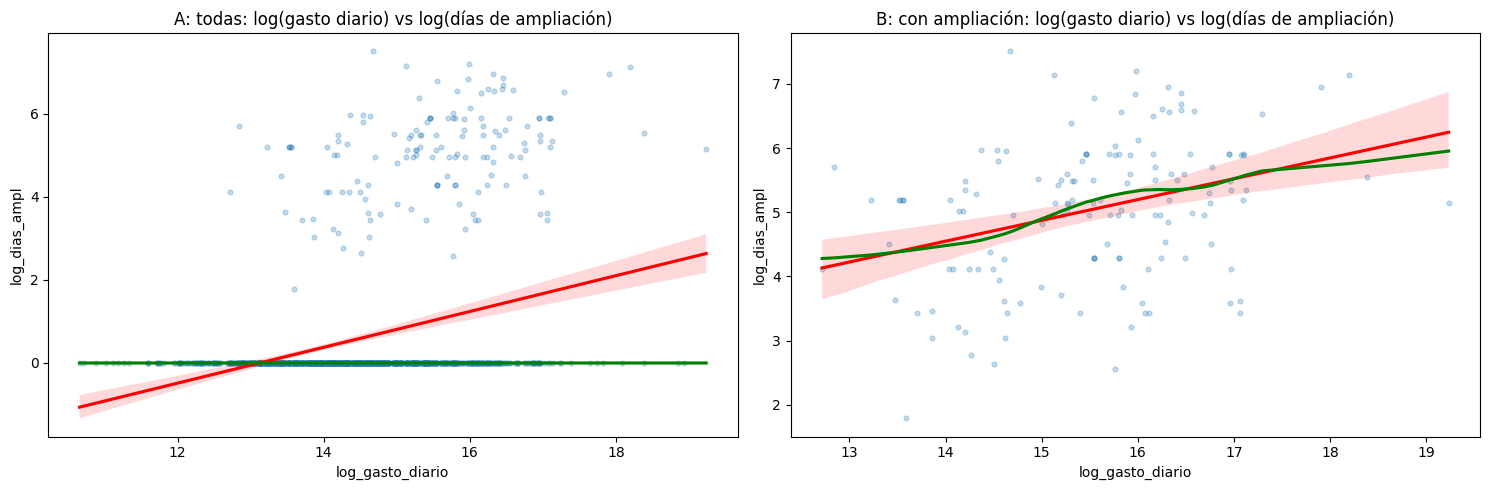

In [9]:
# Linealidad e independencia: diagrama de dispersión con ajuste lineal y LOWESS
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for a, (nombre, d) in zip(ax, [("A: todas", A), ("B: con ampliación", B)]):
    muestra = d.sample(min(len(d), 4000), random_state=42)
    sns.regplot(data=muestra, x="log_gasto_diario", y="log_dias_ampl",
                scatter_kws={"alpha": 0.25, "s": 12}, line_kws={"color": "red"}, ax=a)
    sns.regplot(data=muestra, x="log_gasto_diario", y="log_dias_ampl", lowess=True,
                scatter=False, line_kws={"color": "green"}, ax=a)
    a.set_title(f"{nombre}: log(gasto diario) vs log(días de ampliación)")
plt.tight_layout()
plt.show()

**Lectura de supuestos.** Con muestras grandes, Shapiro-Wilk rechaza la normalidad ante desviaciones mínimas, por lo que se interpreta junto con los gráficos Q-Q. La independencia se asume por diseño (un registro por adjudicación), con la salvedad de que un mismo proveedor puede repetirse en varias obras. Levene no aplica a esta prueba porque no hay grupos que comparar. Si la normalidad o la linealidad no se sostienen, se prioriza Spearman, que solo requiere una relación monótona.

# **Ejecución de las pruebas**

In [10]:
def fisher_ci(r, n, se_factor=1.0, nivel=0.95):
    z = np.arctanh(r)
    se = np.sqrt(se_factor / (n - 3))
    zc = stats.norm.ppf(1 - (1 - nivel) / 2)
    return np.tanh(z - zc * se), np.tanh(z + zc * se)

def bootstrap_ci(x, y, metodo="spearman", B_rep=2000, nivel=0.95, seed=42):
    r_ = np.random.default_rng(seed)
    x, y = np.asarray(x), np.asarray(y)
    n = len(x)
    vals = np.empty(B_rep)
    for i in range(B_rep):
        idx = r_.integers(0, n, n)
        vals[i] = stats.spearmanr(x[idx], y[idx])[0] if metodo == "spearman" else np.corrcoef(x[idx], y[idx])[0, 1]
    return tuple(np.nanpercentile(vals, [(1 - nivel) / 2 * 100, (1 + nivel) / 2 * 100]))

resultados = []
for nombre, d in [("A: todas", A), ("B: con ampliación", B)]:
    n = len(d)

    # Pearson sobre variables transformadas (log)
    pr = stats.pearsonr(d["log_gasto_diario"], d["log_dias_ampl"])
    ic_p = fisher_ci(pr.statistic, n)
    t_p = pr.statistic * np.sqrt((n - 2) / (1 - pr.statistic**2))
    resultados.append([nombre, "r de Pearson (log-log)", n, pr.statistic, t_p, n - 2, pr.pvalue, ic_p[0], ic_p[1], "Fisher"])

    # Spearman sobre variables originales (invariante a transformaciones monótonas)
    sr = stats.spearmanr(d["gasto_diario"], d["dias_ampliacion_total"])
    ic_s = bootstrap_ci(d["gasto_diario"], d["dias_ampliacion_total"], "spearman")
    t_s = sr.statistic * np.sqrt((n - 2) / (1 - sr.statistic**2))
    resultados.append([nombre, "rho de Spearman", n, sr.statistic, t_s, n - 2, sr.pvalue, ic_s[0], ic_s[1], "Bootstrap"])

res = pd.DataFrame(resultados, columns=["Muestra", "Prueba", "n", "Coef.", "Estadístico t", "gl", "p-value", "IC95% inf", "IC95% sup", "Método IC"])
print(res.round(6).to_string(index=False))

          Muestra                 Prueba    n    Coef.  Estadístico t   gl  p-value  IC95% inf  IC95% sup Método IC
         A: todas r de Pearson (log-log) 1240 0.324562      12.073376 1238 0.000000   0.273840   0.373483    Fisher
         A: todas        rho de Spearman 1240 0.302241      11.156193 1238 0.000000   0.250653   0.349307 Bootstrap
B: con ampliación r de Pearson (log-log)  143 0.339028       4.279162  141 0.000034   0.185185   0.476651    Fisher
B: con ampliación        rho de Spearman  143 0.330434       4.157193  141 0.000056   0.184539   0.467818 Bootstrap


# **Corrección por comparaciones múltiples**



In [ ]:
# calcular p-values ajustados por Bonferroni y Holm,y tambien los coeficiente de las pruebas y tomamos decisiones sobre la hipótesis nula
#Se realizaron cuatro pruebas sobre la misma familia de hipótesis (relación entre gasto diario y días de ampliación).
#  Con α = 0,05 por prueba, la probabilidad de al menos un falso positivo en la familia supera el 5 %,
#  por lo que se aplica la corrección de **Bonferroni** (α ajustado = 0,05 / 4 = 0,0125), que controla el error tipo I familiar.
#  Se reporta también Holm como contraste de robustez.
# se divide el alpha entre el número de pruebas para obtener el alpha ajustado por Bonferroni, y se calcula el p-value ajustado por Holm.

p = res["p-value"].values
res["p Bonferroni"] = multipletests(p, alpha=alpha, method="bonferroni")[1]
res["p Holm"] = multipletests(p, alpha=alpha, method="holm")[1]
res["Decisión (Bonferroni)"] = np.where(res["p Bonferroni"] < alpha, "Rechazar H0", "No rechazar H0")

print("α ajustado por Bonferroni =", alpha / len(p))
print(res[["Muestra", "Prueba", "Coef.", "p-value", "p Bonferroni", "p Holm", "Decisión (Bonferroni)"]].round(6).to_string(index=False))

α ajustado por Bonferroni = 0.0125
          Muestra                 Prueba    Coef.  p-value  p Bonferroni   p Holm Decisión (Bonferroni)
         A: todas r de Pearson (log-log) 0.324562 0.000000      0.000000 0.000000           Rechazar H0
         A: todas        rho de Spearman 0.302241 0.000000      0.000000 0.000000           Rechazar H0
B: con ampliación r de Pearson (log-log) 0.339028 0.000034      0.000138 0.000069           Rechazar H0
B: con ampliación        rho de Spearman 0.330434 0.000056      0.000223 0.000069           Rechazar H0


# **Efecto de la variable controlando otras (confusión)**


In [ ]:

#El gasto diario depende del plazo contractual (`monto / plazo`), y el plazo también se relaciona con cuántos días se pueden ampliar.
#  Para ver si la asociación persiste al controlar esas variables, se ajusta una regresión lineal múltiple con errores robustos (HC3)
#  sobre las obras con ampliación y controlando por plazo. No se incluye `log_monto` porque `log(gasto) = log(monto) − log(plazo)` generaría
#  colinealidad perfecta.
reg_df = datos[datos["dias_ampliacion_total"] > 0].dropna(subset=["log_gasto_diario", "log_dias_ampl", "log_plazo"])

modelo = smf.ols("log_dias_ampl ~ log_gasto_diario + log_plazo ", data=reg_df).fit(cov_type="HC3")
print(modelo.summary().tables[1])
print("\nF global (robusto): F =", round(float(modelo.fvalue), 3), "| p =", float(modelo.f_pvalue))
print("R² =", round(modelo.rsquared, 4))

ic = modelo.conf_int().loc["log_gasto_diario"]
print(f"\nCoeficiente de log_gasto_diario: {modelo.params['log_gasto_diario']:.4f} "
      f"(IC95% [{ic[0]:.4f}, {ic[1]:.4f}]), p = {modelo.pvalues['log_gasto_diario']:.4g}")

                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           -1.0164      1.194     -0.851      0.395      -3.357       1.324
log_gasto_diario     0.3155      0.078      4.043      0.000       0.163       0.468
log_plazo            0.2315      0.092      2.513      0.012       0.051       0.412

F global (robusto): F = 14.561 | p = 1.7980678377907113e-06
R² = 0.1617

Coeficiente de log_gasto_diario: 0.3155 (IC95% [0.1625, 0.4685]), p = 5.284e-05


# **Resumen automático de resultados**

In [ ]:
#Aqui calculamos automaticamente la magnitud del efecto de la correlacion segun Cohen (1988),
#  si es despreciable, pequeño, moderado o grande.
# tambien calculamos si la relacion es positiva o negativa, segun el signo del coeficiente de correlacion,
#  el intervalo de confianza y el p-value.

def magnitud(r):
    r = abs(r)
    # Magnitud del efecto según Cohen (1988), si es despreciable, pequeño, moderado o grande.
    return "despreciable" if r < 0.1 else "pequeño" if r < 0.3 else "moderado" if r < 0.5 else "grande"

for _, f in res.iterrows():
    #si es mayor que cero, la relacion es positiva, si es menor que cero, la relacion es negativa.
    #si p es menor que 0.05, rechazamos la hipotesis nula, si es mayor que 0.05, no rechazamos la hipotesis nula.
    sentido = "positiva" if f["Coef."] > 0 else "negativa"
    print(f"{f['Muestra']} | {f['Prueba']}: coef = {f['Coef.']:.4f} ({sentido}, efecto {magnitud(f['Coef.'])}), "
          f"IC95% [{f['IC95% inf']:.4f}, {f['IC95% sup']:.4f}], "
          f"p = {f['p-value']:.3g}, p Bonferroni = {f['p Bonferroni']:.3g} -> {f['Decisión (Bonferroni)']}")

A: todas | r de Pearson (log-log): coef = 0.3246 (positiva, efecto moderado), IC95% [0.2738, 0.3735], p = 8.27e-32, p Bonferroni = 3.31e-31 -> Rechazar H0
A: todas | rho de Spearman: coef = 0.3022 (positiva, efecto moderado), IC95% [0.2507, 0.3493], p = 1.32e-27, p Bonferroni = 5.26e-27 -> Rechazar H0
B: con ampliación | r de Pearson (log-log): coef = 0.3390 (positiva, efecto moderado), IC95% [0.1852, 0.4767], p = 3.44e-05, p Bonferroni = 0.000138 -> Rechazar H0
B: con ampliación | rho de Spearman: coef = 0.3304 (positiva, efecto moderado), IC95% [0.1845, 0.4678], p = 5.56e-05, p Bonferroni = 0.000223 -> Rechazar H0


# **Interpretación**

Se evaluó la relación entre el gasto diario de una obra (monto adjudicado / plazo contractual) y los días de ampliación solicitados en las adjudicaciones de obra pública (`categoria_principal = works`), con un nivel de significancia de 0,05. Las variables presentaron una distribución muy desigual y, en la muestra completa (incluyendo las obras sin ampliación), no cumplieron con el supuesto de normalidad (Shapiro-Wilk, p < 0,001 para el log del gasto diario y para el log de los días de ampliación). Esto último se debe principalmente a la gran cantidad de obras que tienen cero días de ampliación.

Por este motivo, se priorizó la correlación de Spearman, que permite medir la relación entre variables sin exigir una distribución normal, y se complementó con la correlación de Pearson utilizando variables transformadas con logaritmos. Se analizaron todas las obras (n = 1.240) y, por separado, las que solicitaron ampliación (n = 143, el 11,5 % del total). En esta segunda muestra, los resultados del test de Shapiro-Wilk no mostraron evidencia suficiente para rechazar la normalidad (p = 0,258 para el gasto diario y p = 0,053 para los días de ampliación). Por ello, se utilizaron ambos métodos, que llegaron a la misma conclusión. También se aplicó la corrección de Bonferroni para las cuatro pruebas, estableciendo un nivel de significancia ajustado de 0,0125. Los resultados muestran una relación positiva de magnitud moderada: ambas variables tienden a aumentar juntas.

En la muestra completa se encontró una relación positiva y estadísticamente significativa: rho de Spearman = 0,302 (IC95 % [0,251; 0,349]; t(1.238) = 11,16; p ajustado < 0,001) y r de Pearson = 0,325 (IC95 % [0,274; 0,373]; t(1.238) = 12,07; p ajustado < 0,001).

Entre las obras que solicitaron ampliación, la relación fue similar: rho = 0,330 (IC95 % [0,185; 0,468]; t(141) = 4,16; p ajustado = 0,0002) y r = 0,339 (IC95 % [0,185; 0,477]; t(141) = 4,28; p ajustado = 0,0001). Las cuatro pruebas permiten rechazar la hipótesis nula (H₀), y la corrección de Holm llevó a la misma decisión que Bonferroni. Además, los intervalos de confianza no incluyen el cero, lo que respalda la existencia de una relación positiva. Los intervalos de ambas muestras se superponen ampliamente, por lo que no hay evidencia clara de que la relación sea diferente entre ellas. Sin embargo, el resultado de las 143 obras es menos preciso debido al menor tamaño de la muestra.

**Significancia estadística vs. relevancia práctica.** No basta con que una relación sea estadísticamente significativa: también importa qué tan fuerte es. En este caso, la correlación tiene una magnitud moderada (|ρ| aprox 0,30 a 0,34), y la relación también aparece en la muestra de 143 obras, por lo que no se observa únicamente al analizar una gran cantidad de datos. En el caso de Pearson, al elevar sus coeficientes al cuadrado, se obtiene aproximadamente entre un 9 % y un 11 %, que representa la proporción de variabilidad asociada con la relación lineal en el análisis simple. Esto indica que existe una tendencia útil para estudiar las obras, pero que el gasto diario por sí solo no permite predecir con precisión cuántos días de ampliación tendrá una obra. La mayor parte de la variabilidad sigue sin explicarse con esta relación.

**Controlando otras variables.** Para comprobar si la relación se mantiene al considerar el plazo contractual, se realizó una regresión múltiple sobre las 143 obras que solicitaron ampliación, utilizando errores robustos HC3. El coeficiente del log del gasto diario fue 0,316 (IC95 % [0,163; 0,469]; p < 0,001). Esto significa que, manteniendo constante el plazo contractual, un aumento del 1 % en el gasto diario se asocia con un aumento aproximado del 0,32 % en los días de ampliación. Por ejemplo, si el gasto diario aumenta un 10 % y el plazo contractual permanece igual, la cantidad de días de ampliación aumentaría aproximadamente un 3,1 %. Para una obra con 30 días de ampliación, esto equivaldría a unos 0,9 días adicionales. Se trata de una estimación del modelo, no de una predicción exacta para cada obra.

El coeficiente del gasto diario se mantuvo positivo en todo su intervalo de confianza y fue estadísticamente significativo. Esto indica que la relación no desaparece al considerar el plazo contractual. A su vez, el plazo también mostró una relación positiva con los días de ampliación (coeficiente = 0,232; p = 0,012): manteniendo constante el gasto diario, las obras con plazos más largos tienden a solicitar más días adicionales. El modelo completo fue estadísticamente significativo (F = 14,56; p < 0,001) y explicó el 16,2 % de la variabilidad de los días de ampliación en la escala transformada utilizada (R² = 0,162). Esto muestra que el gasto diario y el plazo aportan información, aunque todavía queda una gran parte de la variabilidad sin explicar.

**Variable de confusión.** El plazo contractual es una variable importante que podría influir en la relación observada, porque se utiliza para calcular el gasto diario y también puede estar relacionado con la cantidad de días de ampliación. Al incluirlo en la regresión, se comprobó que la relación positiva con el gasto diario se mantiene, por lo que el plazo no explica por sí solo esa asociación.

Como el análisis se limitó a obras públicas, la categoría de contratación no representa una diferencia entre los casos estudiados. Sin embargo, todavía podrían influir el tamaño y la complejidad técnica de cada obra. El monto total no pudo incluirse en el modelo junto con el gasto diario y el plazo debido a la colinealidad perfecta entre estas variables en su forma logarítmica. Esto es importante porque una obra más grande o compleja podría tener un gasto diario mayor y, al mismo tiempo, más imprevistos que provoquen ampliaciones. También podrían influir el proveedor, el año de adjudicación, el clima o la disponibilidad de financiamiento.

**Limitaciones.** Una correlación no implica causalidad: los resultados muestran una relación entre las variables, pero no demuestran que un mayor gasto diario provoque ampliaciones de plazo. Además, el 88,5 % de las obras no presentó ampliaciones, por lo que la gran cantidad de ceros motivó el análisis de dos muestras por separado. La muestra de obras con ampliación es más reducida (n = 143), lo que genera mayor incertidumbre en sus estimaciones. También puede ocurrir que un mismo proveedor aparezca en varias obras, haciendo que algunas observaciones no sean completamente independientes. Por último, el gasto diario depende de la exactitud de los montos adjudicados y los plazos contractuales registrados.

**Conclusión.** Se rechaza H₀ tanto en el conjunto de las obras públicas como entre las que solicitaron ampliación: existe una relación positiva de magnitud moderada entre el gasto diario y los días de ampliación, que persiste al controlar el plazo contractual. Esto respalda H₁, aunque el gasto diario explica solo una parte de la variabilidad y no permite afirmar causalidad.

A pesar de que existe evidencia de que las obras con mayor gasto diario tienden a solicitar mas dias de ampliacion, no es correcto afirmar que es una causa-efecto, ya que podria estar relacionados otros factores como tamaño, la dificultad o complejidad de la obra(variables de confusion) pero es util para la siguiente fase ya que nos encargamos predecir cuales son las obras que que recibir una ampliacion de monto/dias.-